# Robustness figure: OpenProblems PBMC donor 1

The main-text robustness figure, drawn at its final size for the NeurIPS template
(5.5 in text width: `\includegraphics[width=\linewidth]{figures/robustness.pdf}`), from the stored
results of `python -m stack_quality.run` (`results/robustness/pbmc_donor1/`). Nothing is recomputed
here except means and bootstrap intervals.

- Metric: **Pearson Δctrl on the 2,000-HVG panel**, the panel every model is scored on.
- Unit: a target (drug × query cell type × plate, 31 targets); each target's score is first
  averaged over that condition's draws.
- (a) Clean scores: mean over targets, 95% bootstrap interval resampling the 14 drugs.
- (b)–(e) **Paired** change from clean, ΔS = S(σ) − S(clean), computed per target before
  averaging, with 95% drug-bootstrap intervals. Zero is each model's own clean score.

Set `RUN` to another results folder to redraw it from a different run.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

from stack_quality.score import cluster_bootstrap, per_target

ROOT = Path.cwd().resolve()
while not (ROOT / "robustness").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RUN = ROOT / "results/robustness/pbmc_donor1"
METRIC, PANEL = "pearson_deltactrl", "hvg2000"

scores = pd.read_csv(RUN / "scores.csv.gz")
baselines = pd.read_csv(RUN / "baselines.csv.gz")
print(f"{RUN.relative_to(ROOT)}: {scores['condition'].nunique()} conditions, "
      f"{scores['perturbation'].nunique()} targets")

results/robustness/pbmc_donor1: 27 conditions, 31 targets


In [2]:
# Categorical slots in fixed order (validated: CVD-safe). Two hues sit below 3:1 contrast on white,
# so each model also has its own marker, and the legend names every series.
MODELS = {
    "stack": ("STACK (frozen)", "#2a78d6", "o"),
    "tabpfn": ("TabPFN-3.5", "#eb6834", "s"),
    "ridge": ("Ridge", "#1baf7a", "D"),
    "source_effect_copy": ("Copy T-cell effect", "#eda100", "^"),
}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 7, "axes.titlesize": 7.5, "axes.labelsize": 7, "xtick.labelsize": 6.5,
    "ytick.labelsize": 6.5, "legend.fontsize": 7, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.5, "lines.linewidth": 1.2, "lines.markersize": 3.5,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})

clean_t = per_target(scores[scores["arm"] == "clean"], METRIC, PANEL)


def paired(rows, zero=False):
    """Per (severity, model): mean paired change from clean and its drug-bootstrap interval."""
    t = per_target(rows, METRIC, PANEL).merge(
        clean_t[["model", "perturbation", "value"]], on=["model", "perturbation"], suffixes=("", "_clean"))
    t["d"] = t["value"] - t["value_clean"]
    out = []
    for (sev, model), g in t.groupby(["severity", "model"]):
        m, lo, hi = cluster_bootstrap(g, "d", n_boot=2000)
        out.append({"severity": sev, "model": model, "mean": m, "lo": lo, "hi": hi})
    out = pd.DataFrame(out)
    if zero:  # severity 0 is the clean condition itself: change exactly 0
        out = pd.concat([out, pd.DataFrame([{"severity": 0.0, "model": m, "mean": 0.0, "lo": 0.0, "hi": 0.0}
                                            for m in out["model"].unique()])])
    return out


def draw(ax, t, dodge, log=False):
    """Lines with interval bars; models nudged sideways so bars do not overlap."""
    for k, (model, (name, color, marker)) in enumerate(MODELS.items()):
        g = t[t["model"] == model].sort_values("severity")
        offset = (k - (len(MODELS) - 1) / 2) * dodge
        x = g["severity"] * 2 ** offset if log else g["severity"] + offset
        ax.errorbar(x, g["mean"], yerr=[g["mean"] - g["lo"], g["hi"] - g["mean"]], color=color, marker=marker,
                    mec="white", mew=0.5, elinewidth=0.8, capsize=0, label=name)
    ax.axhline(0, color=MUTED, lw=0.6, zorder=1)

saved results/robustness/pbmc_donor1/figures/robustness.pdf and .png (5.5 x 3.9 in)


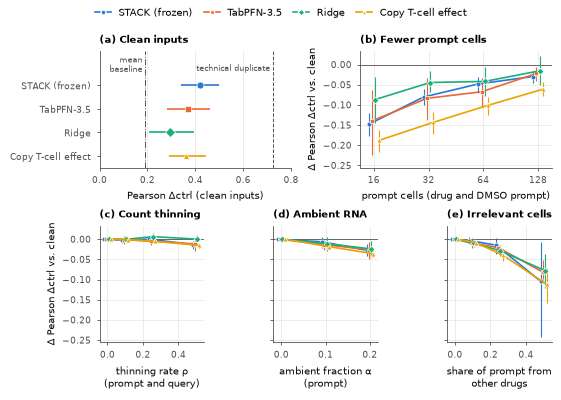

In [3]:
fig = plt.figure(figsize=(5.5, 3.9), layout="constrained")
grid = fig.add_gridspec(2, 6)
a = fig.add_subplot(grid[0, :3])
c = fig.add_subplot(grid[1, :2])
b = fig.add_subplot(grid[0, 3:], sharey=c)  # one y-scale for every change-from-clean panel
d = fig.add_subplot(grid[1, 2:4], sharey=c)
e = fig.add_subplot(grid[1, 4:], sharey=c)
dlabel = "Δ Pearson Δctrl vs. clean"

# (a) clean inputs, with the empirical references
order = list(MODELS)[::-1]
for i, model in enumerate(order):
    g = clean_t[clean_t["model"] == model]
    m, lo, hi = cluster_bootstrap(g, "value", n_boot=2000)
    name, color, marker = MODELS[model]
    a.errorbar(m, i, xerr=[[m - lo], [hi - m]], fmt=marker, color=color, mec="white", mew=0.5, ms=5,
               elinewidth=1.2)
a.set_yticks(range(len(order)), [MODELS[m][0] for m in order])
a.grid(axis="y", visible=False)
refs = (baselines[(baselines["metric"] == METRIC) & (baselines["panel"] == PANEL)]
        .groupby("model")["value"].mean())
for key, label, style, side in (("mean_baseline", "mean\nbaseline", "-.", "right"),
                                ("technical_duplicate", "technical duplicate", "--", "right")):
    a.axvline(refs[key], color=MUTED, ls=style, lw=0.7)
    a.text(refs[key] + (0.01 if side == "left" else -0.01), len(order) - 0.45, label, color=MUTED,
           fontsize=6, ha=side, va="bottom", linespacing=0.95)
a.set_xlim(0, 0.8)
a.set_ylim(-0.5, len(order) + 0.45)
a.set_xlabel("Pearson Δctrl (clean inputs)")
a.set_title("(a) Clean inputs")

# (b) prompt size; zero is the clean prompt (all of the drug's T/NK cells, at most 666)
draw(b, paired(scores[scores["arm"] == "prompt_size"]), dodge=0.06, log=True)
b.set_xscale("log", base=2)
b.set_xticks([16, 32, 64, 128], ["16", "32", "64", "128"])
b.set_xlabel("prompt cells (drug and DMSO prompt)")
b.set_ylabel(dlabel)
b.set_title("(b) Fewer prompt cells")

# (c)-(e) corruption severity; severity 0 is the clean condition
both = scores[(scores["arm"] == "thinning") & (scores["target"] == "both")]
draw(c, paired(both, zero=True), dodge=0.012)
c.set_xlabel("thinning rate ρ\n(prompt and query)")
c.set_ylabel(dlabel)
c.set_title("(c) Count thinning")

amb = scores[(scores["arm"] == "ambient") & (scores["target"] == "prompt")]
draw(d, paired(amb, zero=True), dodge=0.005)
d.set_xlabel("ambient fraction α\n(prompt)")
d.set_title("(d) Ambient RNA")

draw(e, paired(scores[scores["arm"] == "contamination"], zero=True), dodge=0.012)
e.set_xlabel("share of prompt from\nother drugs")
e.set_title("(e) Irrelevant cells")
for ax in (d, e):
    ax.tick_params(labelleft=False)

fig.legend(handles=[Line2D([], [], color=col, marker=mk, mec="white", label=name)
                    for name, col, mk in MODELS.values()],
           loc="outside upper center", ncol=len(MODELS), frameon=False, handlelength=1.6, columnspacing=1.2)
out = RUN / "figures"
out.mkdir(exist_ok=True)
fig.savefig(out / "robustness.pdf")
fig.savefig(out / "robustness.png", dpi=300)
print(f"saved {out.relative_to(ROOT)}/robustness.pdf and .png (5.5 x 3.9 in)")

In [4]:
# Numbers behind panels (b)-(e) at each arm's harshest setting, for the text and Table tab:robust.
rows = []
for label, sub, sev in (("16 prompt cells", scores[scores["arm"] == "prompt_size"], 16),
                        ("thinning 50% (both)", both, 0.5), ("ambient 20% (prompt)", amb, 0.2),
                        ("50% irrelevant prompt", scores[scores["arm"] == "contamination"], 0.5)):
    t = paired(sub)
    for _, r in t[t["severity"] == sev].iterrows():
        if r["model"] in MODELS:
            rows.append({"setting": label, "model": MODELS[r["model"]][0],
                         "change": f"{r['mean']:+.3f} [{r['lo']:+.3f}, {r['hi']:+.3f}]"})
clean_rows = [{"setting": "clean (absolute)", "model": MODELS[m][0],
               "change": "{:.3f} [{:.3f}, {:.3f}]".format(*cluster_bootstrap(clean_t[clean_t["model"] == m], "value"))}
              for m in MODELS]
pd.DataFrame(clean_rows + rows).pivot(index="model", columns="setting", values="change")

setting,16 prompt cells,50% irrelevant prompt,ambient 20% (prompt),clean (absolute),thinning 50% (both)
model,,,,,
Copy T-cell effect,"-0.188 [-0.217, -0.162]","-0.112 [-0.158, -0.071]","-0.036 [-0.045, -0.027]","0.362 [0.292, 0.444]","-0.015 [-0.022, -0.010]"
Ridge,"-0.087 [-0.144, -0.032]","-0.078 [-0.121, -0.036]","-0.024 [-0.045, -0.005]","0.296 [0.205, 0.394]","+0.000 [-0.011, +0.011]"
STACK (frozen),"-0.148 [-0.177, -0.119]","-0.104 [-0.243, -0.008]","-0.027 [-0.041, -0.013]","0.419 [0.342, 0.497]","-0.013 [-0.024, -0.004]"
TabPFN-3.5,"-0.140 [-0.225, -0.064]","-0.081 [-0.109, -0.051]","-0.026 [-0.050, -0.007]","0.371 [0.282, 0.460]","-0.012 [-0.029, +0.001]"
